----------------------------------------------------------
WOMEN'S CLOTHING E-COMMERCE REVIEW ANALYSIS USING PYTHON
---------------------------------------------------------
The aim of this project is to understand customer satisfaction with women's clothing products
main goal is to identify which departments perform better, how customers respond to different products, and what customer reviews tell us about product satisfaction.

In [216]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [217]:
df=pd.read_csv(r"C:\Users\ashiy\Downloads\Telegram Desktop\Womens Clothing E-Commerce Reviews.csv")

print(df)


       Unnamed: 0  Clothing ID  Age  \
0               0          767   33   
1               1         1080   34   
2               2         1077   60   
3               3         1049   50   
4               4          847   47   
...           ...          ...  ...   
23481       23481         1104   34   
23482       23482          862   48   
23483       23483         1104   31   
23484       23484         1084   28   
23485       23485         1104   52   

                                                   Title  \
0                                                    NaN   
1                                                    NaN   
2                                Some major design flaws   
3                                       My favorite buy!   
4                                       Flattering shirt   
...                                                  ...   
23481                     Great dress for many occasions   
23482                         Wish it was made of c

In [218]:
df.drop(columns=["Unnamed: 0"], inplace=True)
print(df)

       Clothing ID  Age                                              Title  \
0              767   33                                                NaN   
1             1080   34                                                NaN   
2             1077   60                            Some major design flaws   
3             1049   50                                   My favorite buy!   
4              847   47                                   Flattering shirt   
...            ...  ...                                                ...   
23481         1104   34                     Great dress for many occasions   
23482          862   48                         Wish it was made of cotton   
23483         1104   31                              Cute, but see through   
23484         1084   28  Very cute dress, perfect for summer parties an...   
23485         1104   52                    Please make more like this one!   

                                             Review Text  Ratin

In [219]:
df.duplicated().sum()


np.int64(21)

In [220]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [221]:
print(df.shape)
df.isna().sum()

(23465, 10)


Clothing ID                   0
Age                           0
Title                      3789
Review Text                 825
Rating                        0
Recommended IND               0
Positive Feedback Count       0
Division Name                14
Department Name              14
Class Name                   14
dtype: int64

In [222]:
# Replace missing values in Title and Review Text.

df["Title"]=df["Title"].fillna("No Title")
df["Review Text"]=df["Review Text"].fillna("No Review")
df.isna().sum()

Clothing ID                 0
Age                         0
Title                       0
Review Text                 0
Rating                      0
Recommended IND             0
Positive Feedback Count     0
Division Name              14
Department Name            14
Class Name                 14
dtype: int64

In [223]:
# remove missing values in Division name, Departtment name, Class name 

df = df.dropna(subset=["Division Name", "Department Name", "Class Name"])
print(df.shape)
df.isna().sum()

(23451, 10)


Clothing ID                0
Age                        0
Title                      0
Review Text                0
Rating                     0
Recommended IND            0
Positive Feedback Count    0
Division Name              0
Department Name            0
Class Name                 0
dtype: int64

In [224]:
print(df.columns)
df.head()

Index(['Clothing ID', 'Age', 'Title', 'Review Text', 'Rating',
       'Recommended IND', 'Positive Feedback Count', 'Division Name',
       'Department Name', 'Class Name'],
      dtype='str')


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,767,33,No Title,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1080,34,No Title,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [225]:
#. number of customers who gave each rating.
df["Rating"].value_counts().sort_index()

Rating
1      842
2     1565
3     2871
4     5076
5    13097
Name: count, dtype: int64

In [226]:
#overall average customer rating.

df["Rating"].mean().round(2)

np.float64(4.19)

In [227]:
# which departments received highest number of recommendation rate

df3=df.groupby("Department Name")["Recommended IND"].mean()*100
df3.sort_values(ascending=False)
# df3.sort_values(ascending=False)

Department Name
Bottoms     85.123749
Intimate    85.014409
Jackets     83.624031
Tops        81.492109
Dresses     80.798479
Trend       73.949580
Name: Recommended IND, dtype: float64

In [228]:
# average rating given by each age group

df.groupby("Age",observed=True)["Rating"].mean().round(2).sort_values(ascending=False)


Age
92    5.00
86    5.00
89    5.00
79    4.93
83    4.81
      ... 
81    3.80
90    3.50
85    3.33
94    3.33
91    3.20
Name: Rating, Length: 77, dtype: float64

In [229]:
# average and positive feed back for each rating

df.groupby("Rating")["Positive Feedback Count"].mean().sort_values()

Rating
5    2.305184
4    2.406028
3    3.145246
2    3.325879
1    3.459620
Name: Positive Feedback Count, dtype: float64

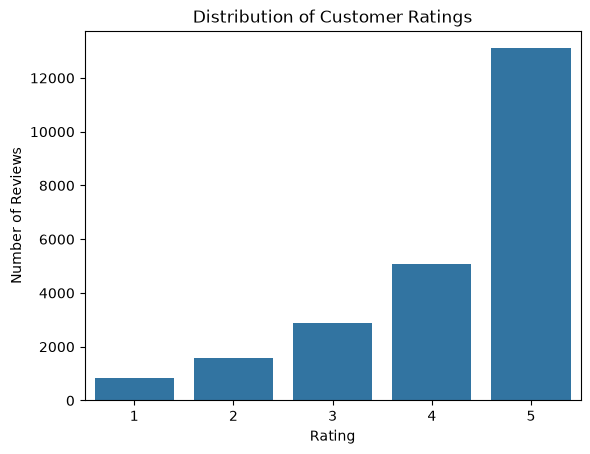

In [230]:
# How are customer ratings distributed?

sns.countplot(data=df, x="Rating")

plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()

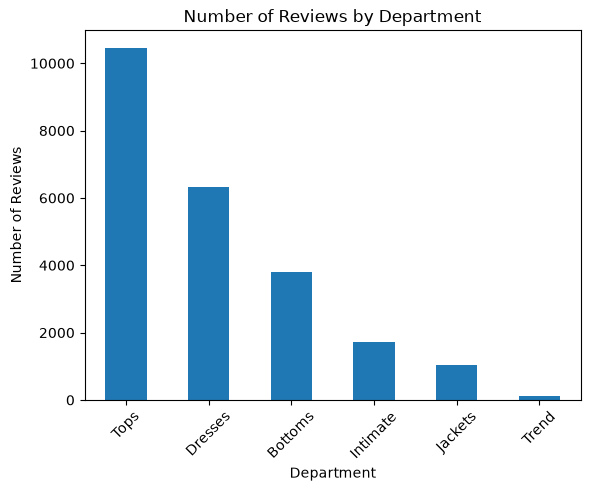

In [231]:
# Which department receives the most reviews?

df["Department Name"].value_counts().plot(kind="bar")

plt.title("Number of Reviews by Department")
plt.xlabel("Department")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.show()

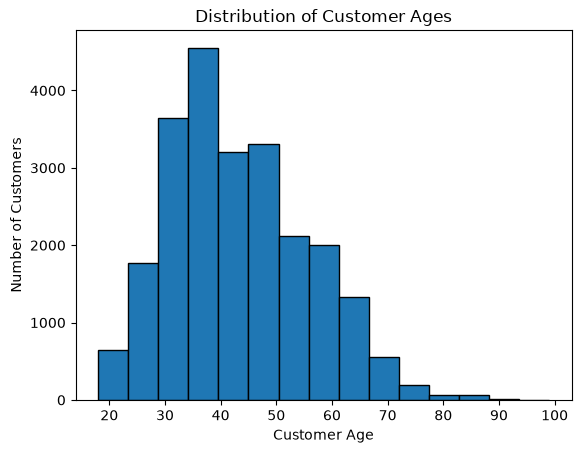

In [232]:
# How are customer ages distributed?

plt.hist(df["Age"], bins=15, edgecolor="black")
plt.title("Distribution of Customer Ages")
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")
plt.show()

In [233]:
# What is the relationship between age, rating, recommendation and positive feedback?
df.corr(numeric_only=True)

,Clothing ID,Age,Rating,Recommended IND,Positive Feedback Count
Clothing ID,1.000000,0.017518,-0.017720,-0.015467,0.045933
Age,0.017518,1.000000,0.027051,0.030786,0.043010
Rating,-0.017720,0.027051,1.000000,0.792281,-0.064569
Recommended IND,-0.015467,0.030786,0.792281,1.000000,-0.068782
Positive Feedback Count,0.045933,0.043010,-0.064569,-0.068782,1.000000


<Axes: >

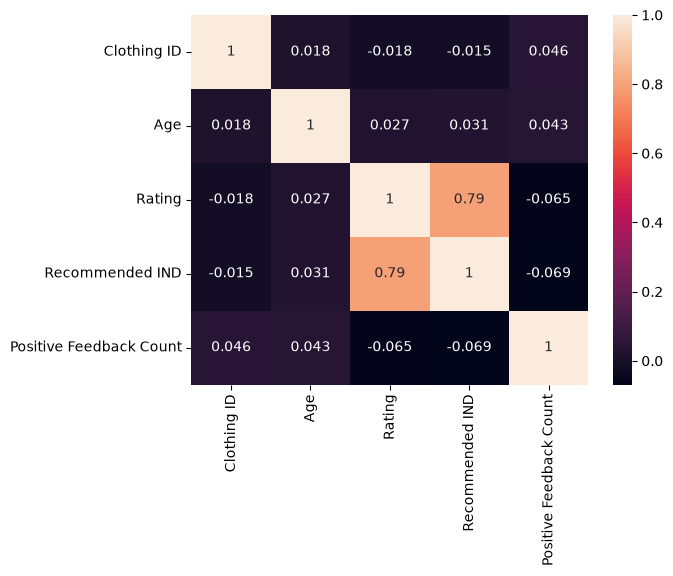

In [234]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

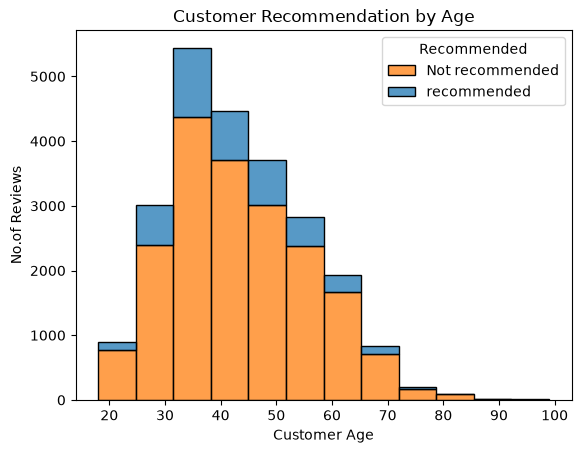

In [235]:
# How customer recommendation behaviour differ  across age group

sns.histplot(data=df,x="Age",bins=12,hue="Recommended IND",multiple="stack")
plt.title("Customer Recommendation by Age")
plt.xlabel("Customer Age")
plt.ylabel("No.of Reviews")
plt.legend(title="Recommended",labels=["Not recommended","recommended"])
plt.show()


In [236]:
# How does the review length differs b/w recommended and nonrecommended


In [237]:
reviews = df[df["Review Text"] != "No Review"].copy() # to remove "no review" value

reviews["Review Length"] = reviews["Review Text"].str.len() # to get the no.of vcharacters

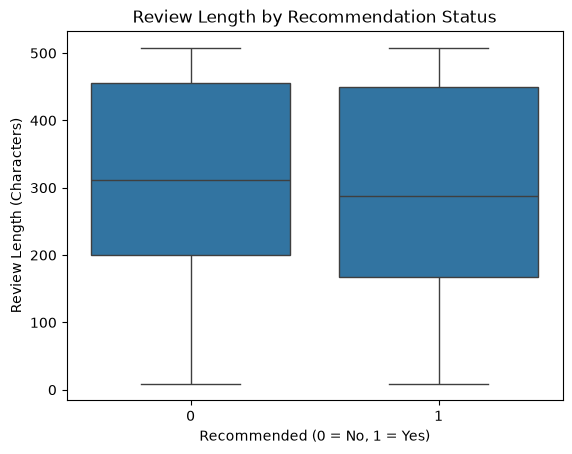

In [238]:

df["Review_Length"]=df["Review Text"].str.len()
sns.boxplot(data=df, x="Recommended IND", y="Review_Length")

plt.title("Review Length by Recommendation Status")
plt.xlabel("Recommended (0 = No, 1 = Yes)")
plt.ylabel("Review Length (Characters)")
plt.show()

-------------------
CONCLUSION
---------------
The analysis showed that customers are generally satisfied with women's clothing products, with an average rating of 4.2 out of 5.

Bottoms had the highest recommendation rate, while Trend had the lowest.

Overall, the project helped me understand customer satisfaction and product performance through reviews and ratings.